# Big Data - Australia Rain Prediction

Nom : Felipe Mateus FALCÃO BARRETO

Date : 12 novembre 2026

L'objectif du projet est de développer un modèle de Machine Learning capable de prédire s'il pleuvra un jour donné, en utilisant comme variables d'entrée les données météorologiques enregistrées la veille.

En termes de classification binaire :

- 1 : Il pleuvra le lendemain.

- 0 : Il ne pleuvra pas le lendemain.

Le notebook s’exécute de bout en bout.

### Libs

In [28]:
import matplotlib.pyplot as plt
import os
from pyspark.ml import Pipeline
from pyspark.ml.feature import (Imputer, StringIndexer, OneHotEncoder, VectorAssembler)
from pyspark.sql import SparkSession
from pyspark.sql.functions import col, sum, when, round, to_date, year, month, dayofweek, avg
from pyspark.ml.classification import LogisticRegression
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from pyspark.ml.evaluation import (MulticlassClassificationEvaluator, BinaryClassificationEvaluator)
import seaborn as sns
import pandas as pd
from sklearn.metrics import roc_curve



## Data

### Java and PySpark configuration

In [2]:
os.environ["JAVA_HOME"] = "/usr/lib/jvm/java-21-openjdk-amd64"
os.environ["PATH"] = os.environ["JAVA_HOME"] + "/bin:" + os.environ["PATH"]
os.environ["SPARK_LOCAL_IP"] = "127.0.0.1"

spark = SparkSession.builder.appName("RainAustralia").master("local[*]").config("spark.driver.memory", "4g").config("spark.ui.showConsoleProgress", "false").getOrCreate()

spark.sparkContext.setLogLevel("ERROR")

print(spark.version)

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/12 20:57:19 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


3.5.7


### Data importation

In [3]:
df = spark.read.csv("hdfs://localhost:8020/rain/input/weatherAUS.csv", header=True, inferSchema=True, nullValue='NA')
print("Total records:", df.count())
df.show(5)

Total records: 145460
+----------+--------+-------+-------+--------+-----------+--------+-----------+-------------+----------+----------+------------+------------+-----------+-----------+-----------+-----------+--------+--------+-------+-------+---------+------------+
|      Date|Location|MinTemp|MaxTemp|Rainfall|Evaporation|Sunshine|WindGustDir|WindGustSpeed|WindDir9am|WindDir3pm|WindSpeed9am|WindSpeed3pm|Humidity9am|Humidity3pm|Pressure9am|Pressure3pm|Cloud9am|Cloud3pm|Temp9am|Temp3pm|RainToday|RainTomorrow|
+----------+--------+-------+-------+--------+-----------+--------+-----------+-------------+----------+----------+------------+------------+-----------+-----------+-----------+-----------+--------+--------+-------+-------+---------+------------+
|2008-12-01|  Albury|   13.4|   22.9|     0.6|       NULL|    NULL|          W|           44|         W|       WNW|          20|          24|         71|         22|     1007.7|     1007.1|       8|    NULL|   16.9|   21.8|       No|    

## Exploratory Data Analysis - EDA

In [4]:
col_names = df.columns
print(f"Dataset shape: {df.count()}, {len(df.columns)}\nColumns: {col_names}\nSchema:")
df.printSchema()

Dataset shape: 145460, 23
Columns: ['Date', 'Location', 'MinTemp', 'MaxTemp', 'Rainfall', 'Evaporation', 'Sunshine', 'WindGustDir', 'WindGustSpeed', 'WindDir9am', 'WindDir3pm', 'WindSpeed9am', 'WindSpeed3pm', 'Humidity9am', 'Humidity3pm', 'Pressure9am', 'Pressure3pm', 'Cloud9am', 'Cloud3pm', 'Temp9am', 'Temp3pm', 'RainToday', 'RainTomorrow']
Schema:
root
 |-- Date: date (nullable = true)
 |-- Location: string (nullable = true)
 |-- MinTemp: double (nullable = true)
 |-- MaxTemp: double (nullable = true)
 |-- Rainfall: double (nullable = true)
 |-- Evaporation: double (nullable = true)
 |-- Sunshine: double (nullable = true)
 |-- WindGustDir: string (nullable = true)
 |-- WindGustSpeed: integer (nullable = true)
 |-- WindDir9am: string (nullable = true)
 |-- WindDir3pm: string (nullable = true)
 |-- WindSpeed9am: integer (nullable = true)
 |-- WindSpeed3pm: integer (nullable = true)
 |-- Humidity9am: integer (nullable = true)
 |-- Humidity3pm: integer (nullable = true)
 |-- Pressure9am:

### Missing data

In [5]:
missing_values = df.select([sum(when(col(c).isNull(), 1).otherwise(0)).alias(c) for c in df.columns])
missing_values.show(vertical=True)


-RECORD 0--------------
 Date          | 0     
 Location      | 0     
 MinTemp       | 1485  
 MaxTemp       | 1261  
 Rainfall      | 3261  
 Evaporation   | 62790 
 Sunshine      | 69835 
 WindGustDir   | 10326 
 WindGustSpeed | 10263 
 WindDir9am    | 10566 
 WindDir3pm    | 4228  
 WindSpeed9am  | 1767  
 WindSpeed3pm  | 3062  
 Humidity9am   | 2654  
 Humidity3pm   | 4507  
 Pressure9am   | 15065 
 Pressure3pm   | 15028 
 Cloud9am      | 55888 
 Cloud3pm      | 59358 
 Temp9am       | 1767  
 Temp3pm       | 3609  
 RainToday     | 3261  
 RainTomorrow  | 3267  



### Target distribution

In [6]:
total = df.count()
df.groupBy("RainTomorrow").count().withColumn("Percentage", round(col("count") / total * 100, 2)).show()


+------------+------+----------+
|RainTomorrow| count|Percentage|
+------------+------+----------+
|        NULL|  3267|      2.25|
|          No|110316|     75.84|
|         Yes| 31877|     21.91|
+------------+------+----------+



### Categorical and numerical columns

In [7]:
categorical = [c for c, dtype in df.dtypes if dtype == "string" and c != "RainTomorrow"]
print(f'There are {len(categorical)} categorical variables\nThe categorical variables are: {categorical}')

df.select(categorical).show(5)

There are 5 categorical variables
The categorical variables are: ['Location', 'WindGustDir', 'WindDir9am', 'WindDir3pm', 'RainToday']
+--------+-----------+----------+----------+---------+
|Location|WindGustDir|WindDir9am|WindDir3pm|RainToday|
+--------+-----------+----------+----------+---------+
|  Albury|          W|         W|       WNW|       No|
|  Albury|        WNW|       NNW|       WSW|       No|
|  Albury|        WSW|         W|       WSW|       No|
|  Albury|         NE|        SE|         E|       No|
|  Albury|          W|       ENE|        NW|       No|
+--------+-----------+----------+----------+---------+
only showing top 5 rows



In [8]:
numerical = [c for c, dtype in df.dtypes if dtype in ("int", "bigint", "float", "double")]
print(f'There are {len(numerical)} numerical variables\nThe numerical variables are: {numerical}')

df.select(numerical).show(5)

There are 16 numerical variables
The numerical variables are: ['MinTemp', 'MaxTemp', 'Rainfall', 'Evaporation', 'Sunshine', 'WindGustSpeed', 'WindSpeed9am', 'WindSpeed3pm', 'Humidity9am', 'Humidity3pm', 'Pressure9am', 'Pressure3pm', 'Cloud9am', 'Cloud3pm', 'Temp9am', 'Temp3pm']
+-------+-------+--------+-----------+--------+-------------+------------+------------+-----------+-----------+-----------+-----------+--------+--------+-------+-------+
|MinTemp|MaxTemp|Rainfall|Evaporation|Sunshine|WindGustSpeed|WindSpeed9am|WindSpeed3pm|Humidity9am|Humidity3pm|Pressure9am|Pressure3pm|Cloud9am|Cloud3pm|Temp9am|Temp3pm|
+-------+-------+--------+-----------+--------+-------------+------------+------------+-----------+-----------+-----------+-----------+--------+--------+-------+-------+
|   13.4|   22.9|     0.6|       NULL|    NULL|           44|          20|          24|         71|         22|     1007.7|     1007.1|       8|    NULL|   16.9|   21.8|
|    7.4|   25.1|     0.0|       NULL|   

### Dataset resume by data type

In [9]:
# Categorical variable analysis
for c in categorical:
    print(f"\n{c}:")
    df.groupBy(c).count().orderBy(col("count").desc()).show()


Location:
+------------+-----+
|    Location|count|
+------------+-----+
|    Canberra| 3436|
|      Sydney| 3344|
|    Brisbane| 3193|
|      Hobart| 3193|
|   Melbourne| 3193|
|    Adelaide| 3193|
|       Perth| 3193|
|      Darwin| 3193|
|  Wollongong| 3040|
|      Albury| 3040|
|     Bendigo| 3040|
|    Ballarat| 3040|
| MountGinini| 3040|
|      Cairns| 3040|
|      Albany| 3040|
|   GoldCoast| 3040|
|MountGambier| 3040|
|  Townsville| 3040|
|AliceSprings| 3040|
|  Launceston| 3040|
+------------+-----+
only showing top 20 rows


WindGustDir:
+-----------+-----+
|WindGustDir|count|
+-----------+-----+
|       NULL|10326|
|          W| 9915|
|         SE| 9418|
|          N| 9313|
|        SSE| 9216|
|          E| 9181|
|          S| 9168|
|        WSW| 9069|
|         SW| 8967|
|        SSW| 8736|
|        WNW| 8252|
|         NW| 8122|
|        ENE| 8104|
|        ESE| 7372|
|         NE| 7133|
|        NNW| 6620|
|        NNE| 6548|
+-----------+-----+


WindDir9am:
+----------

In [10]:
# Numerical variable analysis
df.select(numerical).describe().show()

+-------+------------------+------------------+-----------------+-----------------+------------------+------------------+------------------+------------------+------------------+-----------------+------------------+-----------------+------------------+------------------+------------------+------------------+
|summary|           MinTemp|           MaxTemp|         Rainfall|      Evaporation|          Sunshine|     WindGustSpeed|      WindSpeed9am|      WindSpeed3pm|       Humidity9am|      Humidity3pm|       Pressure9am|      Pressure3pm|          Cloud9am|          Cloud3pm|           Temp9am|           Temp3pm|
+-------+------------------+------------------+-----------------+-----------------+------------------+------------------+------------------+------------------+------------------+-----------------+------------------+-----------------+------------------+------------------+------------------+------------------+
|  count|            143975|            144199|           142199|     

### Distribution of the target data

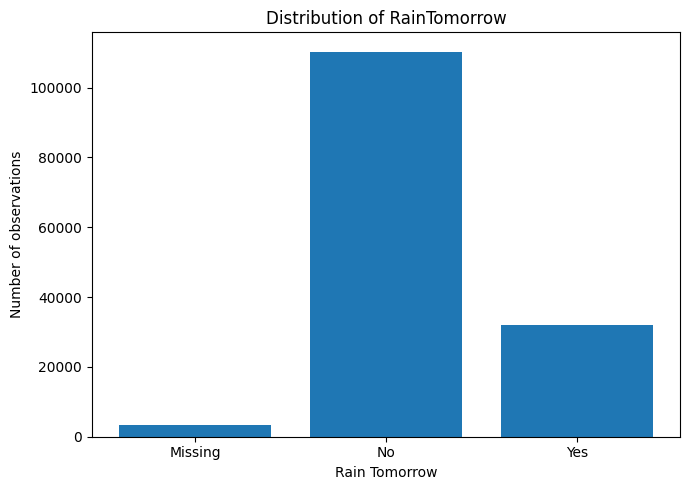

In [11]:
target_counts = df.groupBy("RainTomorrow").count().toPandas()

# Replace null category with "Missing"
target_counts["RainTomorrow"] = target_counts["RainTomorrow"].fillna("Missing")

plt.figure(figsize=(7, 5))
plt.bar(target_counts["RainTomorrow"], target_counts["count"])
plt.title("Distribution of RainTomorrow")
plt.xlabel("Rain Tomorrow")
plt.ylabel("Number of observations")
plt.tight_layout()
plt.show()

On observe une prédominance de jours sans pluie nettement supérieure à toute autre donnée, ce qui peut influencer le résultat de la prévision.

### Top 10 locations with highest rain probability

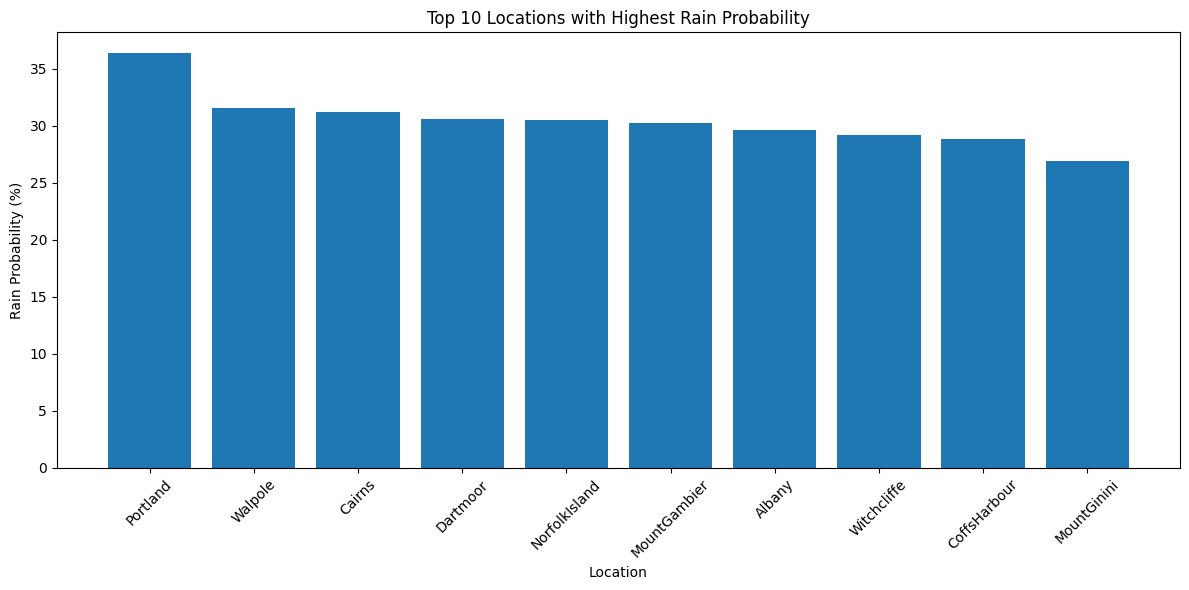

In [12]:
location_rain = df.groupBy("Location").agg((avg(when(col("RainTomorrow") == "Yes", 1).otherwise(0)) * 100).alias("Rain_Percentage")).orderBy("Rain_Percentage", ascending=False).toPandas()


plt.figure(figsize=(12, 6))
plt.bar(location_rain["Location"].head(10), location_rain["Rain_Percentage"].head(10))
plt.title("Top 10 Locations with Highest Rain Probability")
plt.xlabel("Location")
plt.ylabel("Rain Probability (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Certaines villes peuvent influencer les prévisions du modèle. C'est le cas, par exemple, de Portland, qui a connu beaucoup plus de pluie que les autres villes.

### Target variable Vs numerical data at 9am

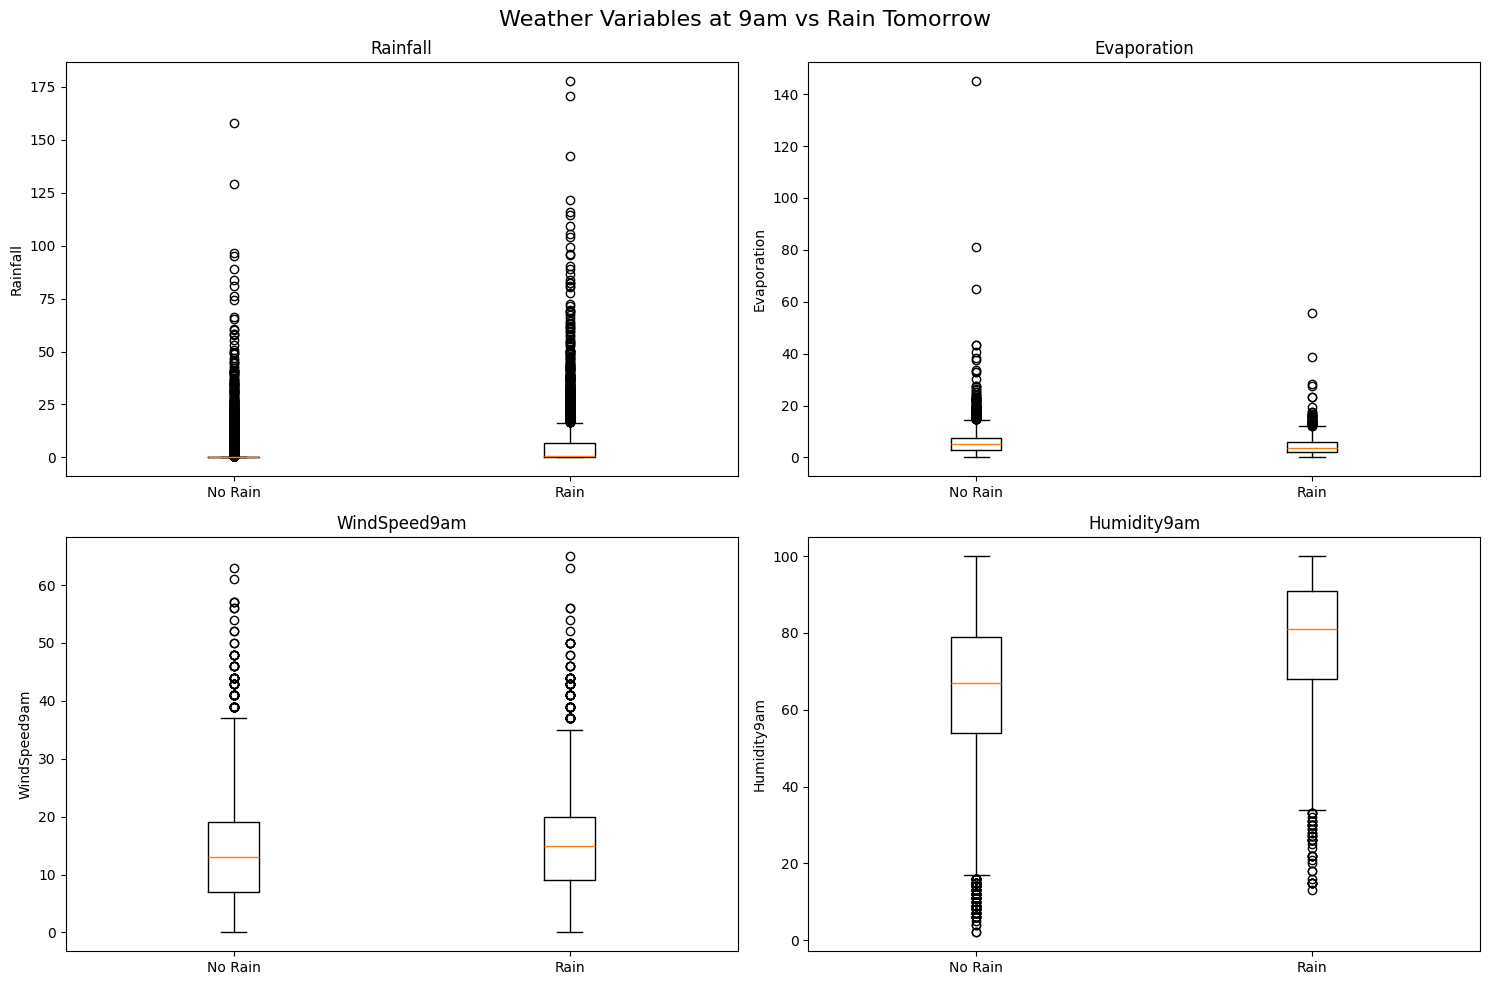

In [13]:
sample = df.select("Rainfall", "Evaporation", "WindSpeed9am","Humidity9am", "RainTomorrow").sample(False, 0.1, seed=42).toPandas()
columns = ["Rainfall", "Evaporation", "WindSpeed9am", "Humidity9am"]
plt.figure(figsize=(15, 10))


for i, column in enumerate(columns, 1):
    plt.subplot(2, 2, i)
    groups = [sample[sample["RainTomorrow"] == "No"][column].dropna(), sample[sample["RainTomorrow"] == "Yes"][column].dropna()]
    plt.boxplot(groups, tick_labels=["No Rain", "Rain"])
    plt.title(column)
    plt.ylabel(column)

plt.suptitle("Weather Variables at 9am vs Rain Tomorrow", fontsize=16)
plt.tight_layout()
plt.show()

### Target variable Vs numerical data at 9am

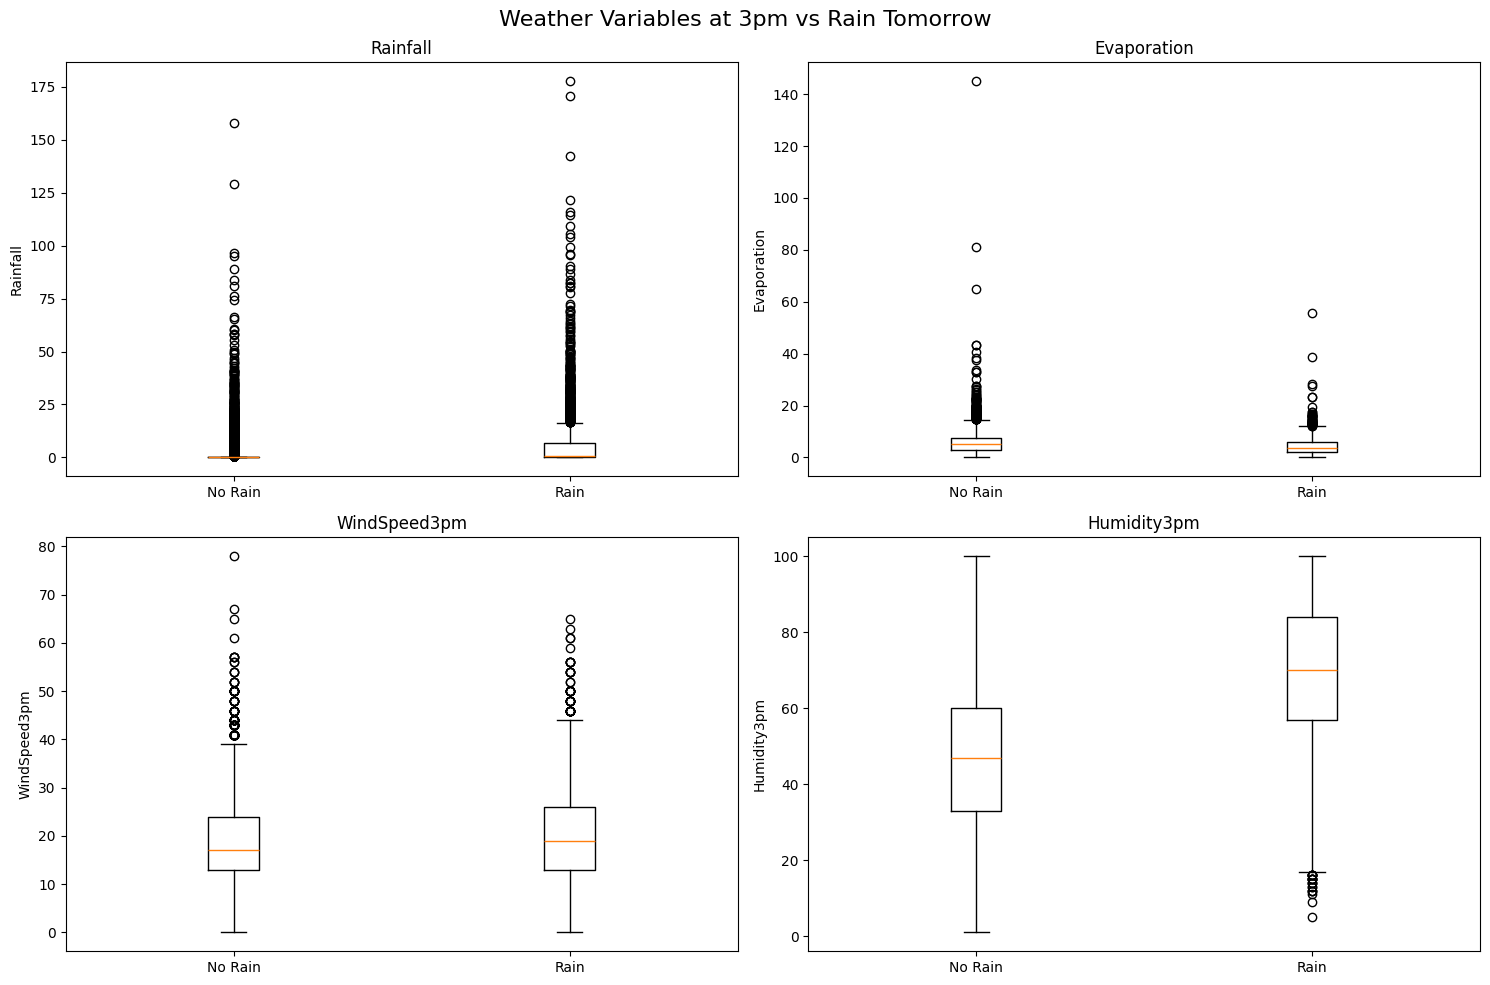

In [14]:
sample = df.select("Rainfall", "Evaporation", "WindSpeed3pm","Humidity3pm", "RainTomorrow").sample(False, 0.1, seed=42).toPandas()
columns = ["Rainfall", "Evaporation", "WindSpeed3pm", "Humidity3pm"]
plt.figure(figsize=(15, 10))

for i, column in enumerate(columns, 1):
    plt.subplot(2, 2, i)
    groups = [sample[sample["RainTomorrow"] == "No"][column].dropna(),sample[sample["RainTomorrow"] == "Yes"][column].dropna()]
    plt.boxplot(groups, tick_labels=["No Rain", "Rain"])
    plt.title(column)
    plt.ylabel(column)
plt.suptitle("Weather Variables at 3pm vs Rain Tomorrow", fontsize=16)
plt.tight_layout()
plt.show()

### Humidity vs Temperature

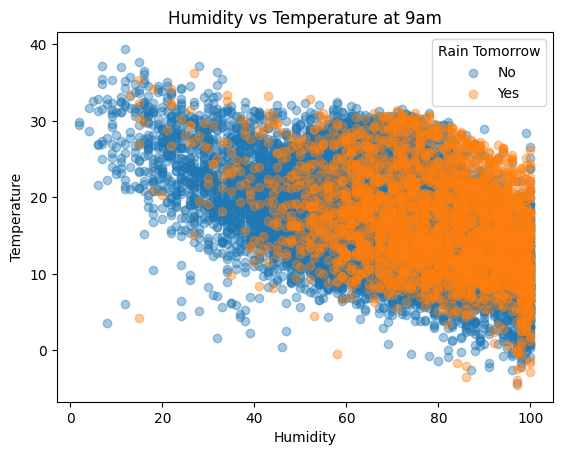

In [15]:
sample = df.select("Humidity9am", "Temp9am", "RainTomorrow").sample(False, 0.1, seed=42).toPandas()


for label, group in sample.groupby("RainTomorrow"):
    if pd.notna(label):
        plt.scatter(group["Humidity9am"], group["Temp9am"], label=label, alpha=0.4)

plt.title("Humidity vs Temperature at 9am")
plt.xlabel("Humidity")
plt.ylabel("Temperature")
plt.legend(title="Rain Tomorrow")
plt.show()

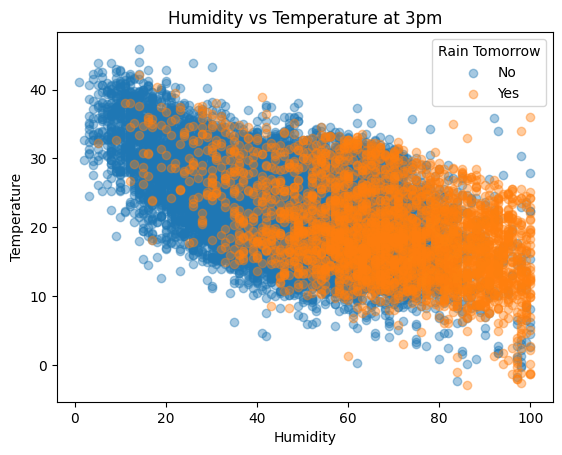

In [16]:
sample = df.select("Humidity3pm", "Temp3pm", "RainTomorrow").sample(False, 0.1, seed=42).toPandas()


for label, group in sample.groupby("RainTomorrow"):
    if pd.notna(label):
        plt.scatter(group["Humidity3pm"], group["Temp3pm"], label=label, alpha=0.4)

plt.title("Humidity vs Temperature at 3pm")
plt.xlabel("Humidity")
plt.ylabel("Temperature")
plt.legend(title="Rain Tomorrow")
plt.show()

### Correlation Heatmap

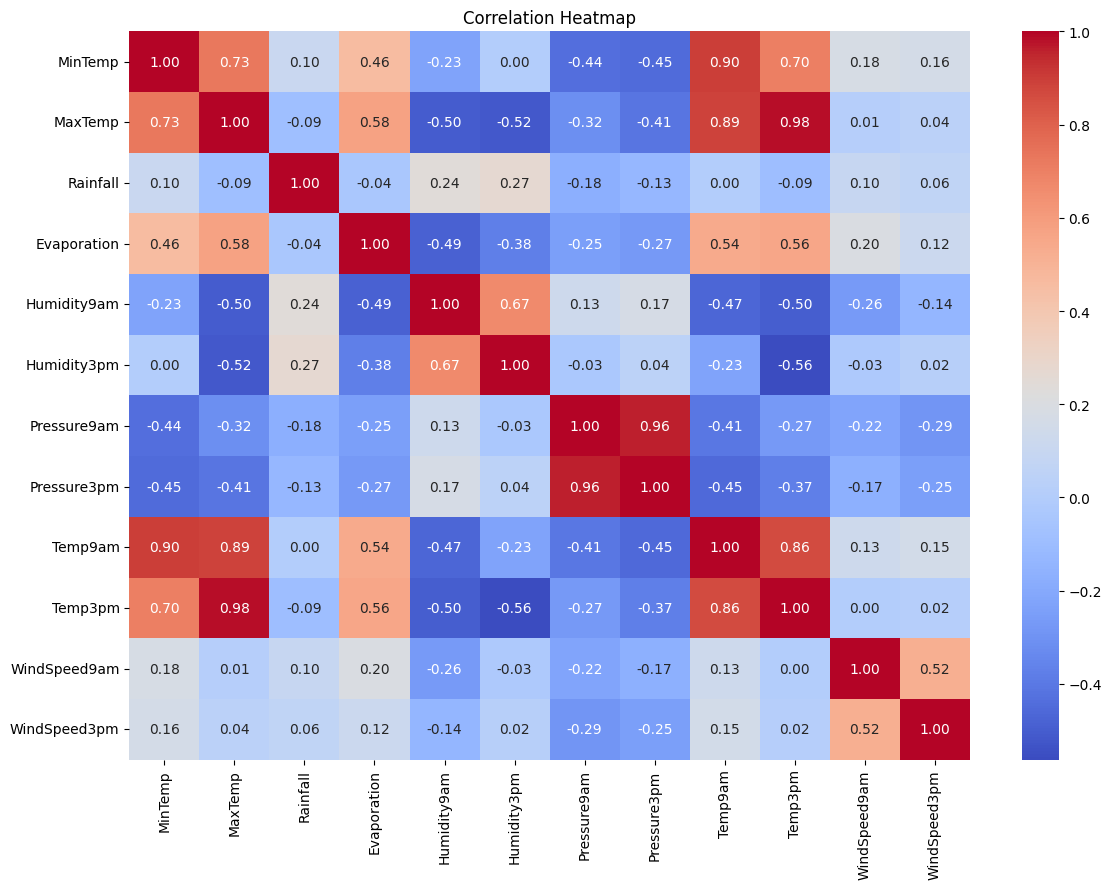

In [17]:

sample = df.select("MinTemp", "MaxTemp", "Rainfall", "Evaporation", "Humidity9am", "Humidity3pm", "Pressure9am", "Pressure3pm", "Temp9am", "Temp3pm", "WindSpeed9am", "WindSpeed3pm").sample(False, 0.1, seed=42).toPandas()
plt.figure(figsize=(12, 9))
sns.heatmap(sample.corr(numeric_only=True), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

## Prétraitement

### Date processing

In [18]:
df = df.withColumn("Date", to_date(col("Date"), "yyyy-MM-dd"))
df = df.withColumn("Year", year(col("Date"))).withColumn("Month", month(col("Date"))).withColumn("DayOfWeek", dayofweek(col("Date"))).drop("Date")

### Removing null targets

In [19]:
df = df.filter(col("RainTomorrow").isNotNull())
print(f"Records after removing missing target: {df.count()}")

Records after removing missing target: 142193


## Data pipeline et Transformation

In [20]:
# Numerical variables
imputed_cols = [c + "_imputed" for c in numerical]
imputer = Imputer(inputCols=numerical, outputCols=imputed_cols, strategy="median")

# Categorical variables
indexers = [StringIndexer(inputCol=c, outputCol=c + "_index", handleInvalid="keep") for c in categorical]
encoded_cols = [c + "_encoded" for c in categorical]
encoder = OneHotEncoder(inputCols=[c + "_index" for c in categorical], outputCols=encoded_cols)

label_indexer = StringIndexer(inputCol="RainTomorrow", outputCol="label", stringOrderType="alphabetAsc")
assemble = VectorAssembler(inputCols=imputed_cols + encoded_cols, outputCol="features")

pipeline = Pipeline(stages=[imputer, *indexers, encoder, label_indexer, assemble])

### Data separation

In [21]:
train_df, test_df = df.randomSplit([0.8, 0.2], seed=42)

print("Training counter:", train_df.count())
print("Testing counter:", test_df.count())

Training counter: 113916
Testing counter: 28277


### Adjusting dataset to machine learning data format

In [22]:
pipeline_model = pipeline.fit(train_df)
train_prepared = pipeline_model.transform(train_df)
test_prepared = pipeline_model.transform(test_df)

### New dataset visualization

In [23]:
train_prepared.select("features", "label").show(5, truncate=False)

+-------------------------------------------------------------------------------------------------------------------------------------------------------------+-----+
|features                                                                                                                                                     |label|
+-------------------------------------------------------------------------------------------------------------------------------------------------------------+-----+
|(115,[0,1,3,4,5,6,7,8,9,10,11,12,13,14,15,23,71,81,104],[12.0,11.8,4.8,8.5,28.0,2.0,19.0,97.0,65.0,1019.5,1018.3,7.0,4.0,6.7,11.3,1.0,1.0,1.0,1.0])          |0.0  |
|(115,[0,1,3,4,5,6,7,8,9,10,11,12,13,14,15,23,65,88,104],[12.0,18.5,4.8,8.5,37.0,17.0,17.0,73.0,52.0,1016.4,1015.8,5.0,1.0,11.4,17.8,1.0,1.0,1.0,1.0])        |0.0  |
|(115,[0,1,3,4,5,6,7,8,9,10,11,12,13,14,15,23,78,93,108,113],[12.0,22.3,4.8,8.5,37.0,24.0,17.0,74.0,93.0,1008.8,1006.6,8.0,8.0,20.9,20.1,1.0,1.0,1.0,1.0,1.0])|1.0  |
|(11

## Machine Learning

### Model training

In [24]:
lr = LogisticRegression(featuresCol="features", labelCol="label", maxIter=100, regParam=0.01)
model = lr.fit(train_prepared)

### Model test

In [25]:
predictions = model.transform(test_prepared)
predictions.select("label", "prediction", "probability").show(50, truncate=False)

+-----+----------+-----------------------------------------+
|label|prediction|probability                              |
+-----+----------+-----------------------------------------+
|0.0  |0.0       |[0.8238978154393721,0.17610218456062787] |
|0.0  |0.0       |[0.9616192769521141,0.03838072304788587] |
|1.0  |0.0       |[0.7514860564770661,0.24851394352293388] |
|0.0  |0.0       |[0.9664939258223966,0.03350607417760343] |
|0.0  |0.0       |[0.9861292205375819,0.013870779462418104]|
|0.0  |0.0       |[0.9626842203193596,0.03731577968064037] |
|0.0  |0.0       |[0.9814729521064787,0.01852704789352133] |
|0.0  |0.0       |[0.8382009881977103,0.16179901180228973] |
|0.0  |0.0       |[0.9471635080985776,0.05283649190142237] |
|0.0  |0.0       |[0.9706827935202628,0.029317206479737234]|
|0.0  |0.0       |[0.8832412615041545,0.1167587384958455]  |
|0.0  |0.0       |[0.9830005396403907,0.01699946035960931] |
|0.0  |0.0       |[0.9398766383318784,0.0601233616681216]  |
|0.0  |0.0       |[0.974

## Model evaluation

In [26]:
accuracy = MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction", metricName="accuracy").evaluate(predictions)
f1 = MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction", metricName="f1").evaluate(predictions)
auc = BinaryClassificationEvaluator(labelCol="label",rawPredictionCol="rawPrediction",metricName="areaUnderROC").evaluate(predictions)

print(f"Accuracy: {accuracy:.4f}\nF1-score: {f1:.4f}\nAUC-ROC: {auc:.4f}")

Accuracy: 0.8461
F1-score: 0.8348
AUC-ROC: 0.8639


### ROC AUC curve

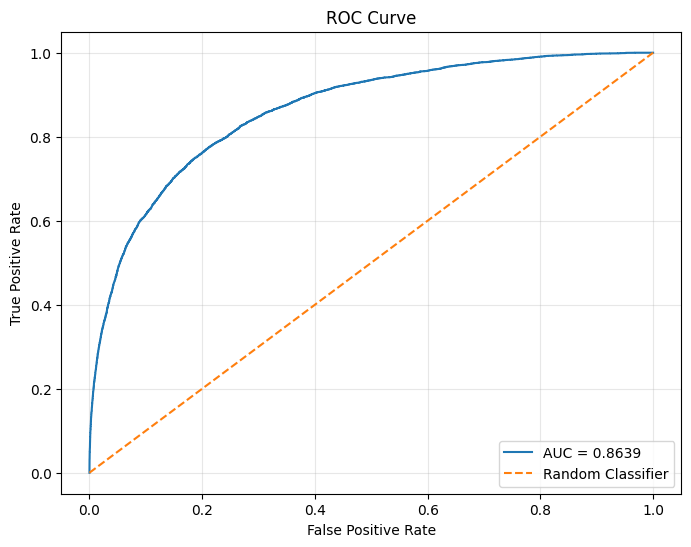

In [29]:
results = predictions.select("label", "probability").toPandas()
fpr, tpr, thresholds = roc_curve(results["label"], results["probability"].apply(lambda x: float(x[1])))

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f"AUC = {auc:.4f}")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")
plt.title("ROC Curve")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

### Confunsion matrix

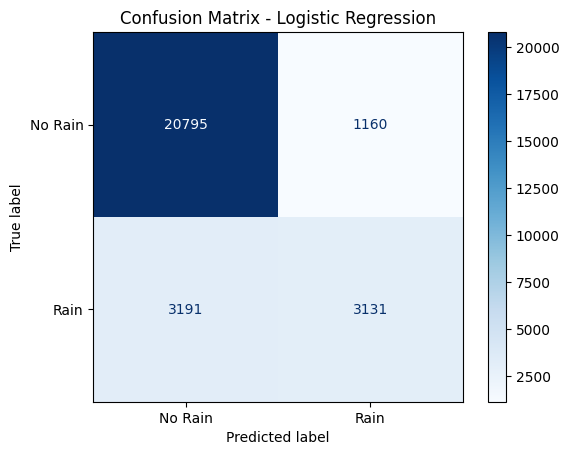

In [30]:
results = predictions.select("label", "prediction").toPandas()
y_true = results["label"]
y_pred = results["prediction"]

cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["No Rain", "Rain"])
disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix - Logistic Regression")
plt.show()